# Solution for the first science case

In this section, we are visualizing astronomical data from an aperture-based observation, comparing observed and absolute magnitudes of stars. We will plot two graphs side by side, showing the g-i vs. g and the corresponding absolute magnitude corrected for distance modulus.

In [ ]:
# needed Python imports
# imports for data retrieve
import splusdata
import numpy as np
from matplotlib import pyplot as plt

In [2]:
conn = splusdata.Core()

In [48]:
ra = 323.36249
dec = -0.82333

coords = ra, dec
radius = 30*60

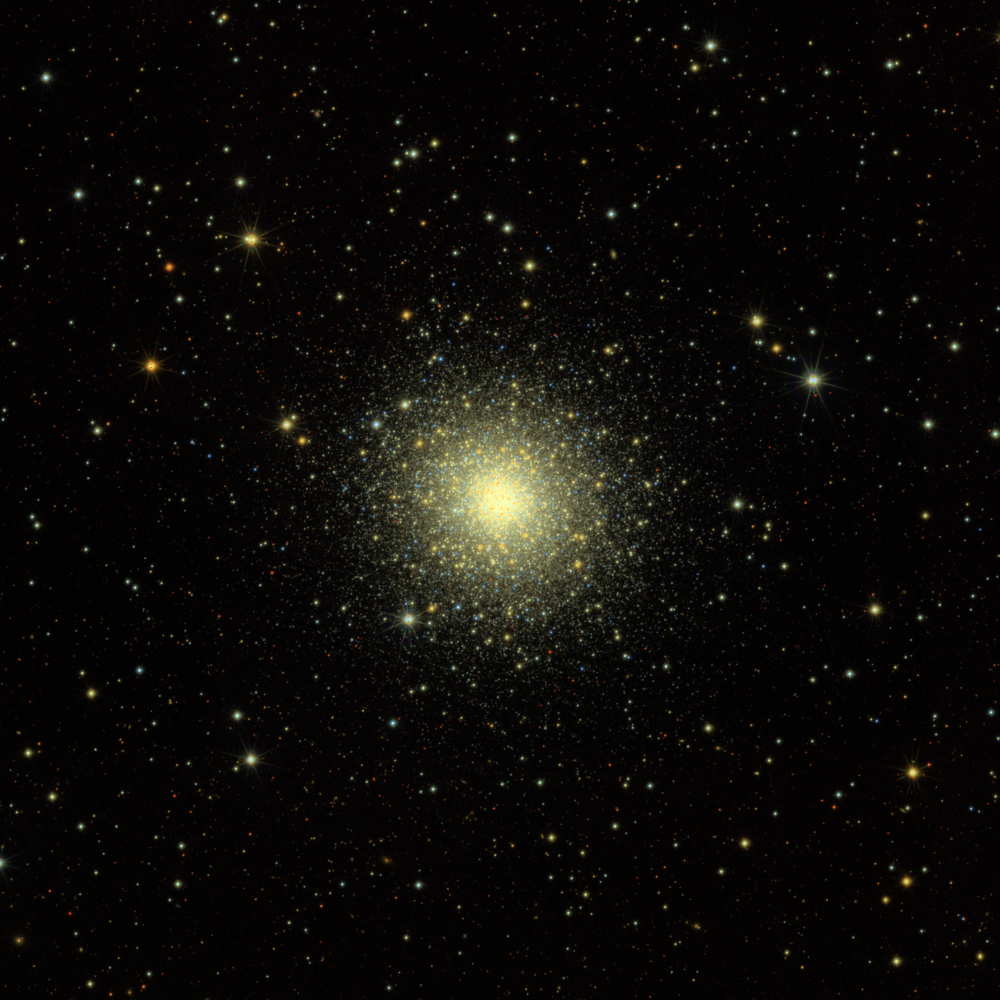

In [4]:
conn.lupton_rgb(ra, dec, radius / 0.55)

## S-PLUS Catalogs choice

In [37]:
from astroquery.gaia import Gaia

def get_gaia_table_esa(ra, dec, radius_arcsec):
    query = f"""
    SELECT
        source_id,
        ra,
        dec,
        pmra,
        pmdec,
        parallax,
        parallax_error,
        phot_rp_mean_mag,
        phot_bp_mean_mag,
        phot_g_mean_mag,
        bp_rp,
        bp_g,
        g_rp
    FROM gaiadr3.gaia_source
    WHERE
        1 = CONTAINS(
            POINT('ICRS', ra, dec),
            CIRCLE('ICRS', {ra}, {dec}, {radius_arcsec} / 3600.0)
        )
        AND ruwe < 1.4
    """

    job = Gaia.launch_job_async(query)
    return job.get_results()

In [38]:
gaia_tab = get_gaia_table_esa(ra=ra, dec=dec, radius_arcsec=radius)

INFO: Query finished. [astroquery.utils.tap.core]


In [39]:
gaia_tab.columns

<TableColumns names=('source_id','ra','dec','pmra','pmdec','parallax','parallax_error','phot_rp_mean_mag','phot_bp_mean_mag','phot_g_mean_mag','bp_rp','bp_g','g_rp')>

In [24]:
splus_tab = conn.query(
    f"""
    SELECT
        i.id,
        i.id_ra AS ra,
        i.id_dec AS dec,

        u.u_psf                    AS mag_psf_u,
        u.e_u_psf                  AS err_psf_u,
        u.s2n_u_psf                AS s2n_psf_u,

        j0378.j0378_psf            AS mag_psf_j0378,
        j0378.e_j0378_psf          AS err_psf_j0378,
        j0378.s2n_j0378_psf        AS s2n_psf_j0378,

        j0395.j0395_psf            AS mag_psf_j0395,
        j0395.e_j0395_psf          AS err_psf_j0395,
        j0395.s2n_j0395_psf        AS s2n_psf_j0395,

        j0410.j0410_psf            AS mag_psf_j0410,
        j0410.e_j0410_psf          AS err_psf_j0410,
        j0410.s2n_j0410_psf        AS s2n_psf_j0410,

        j0430.j0430_psf            AS mag_psf_j0430,
        j0430.e_j0430_psf          AS err_psf_j0430,
        j0430.s2n_j0430_psf        AS s2n_psf_j0430,

        g.g_psf                    AS mag_psf_g,
        g.e_g_psf                  AS err_psf_g,
        g.s2n_g_psf                AS s2n_psf_g,

        j0515.j0515_psf            AS mag_psf_j0515,
        j0515.e_j0515_psf          AS err_psf_j0515,
        j0515.s2n_j0515_psf        AS s2n_psf_j0515,

        r.r_psf                    AS mag_psf_r,
        r.e_r_psf                  AS err_psf_r,
        r.s2n_r_psf                AS s2n_psf_r,

        j0660.j0660_psf            AS mag_psf_j0660,
        j0660.e_j0660_psf          AS err_psf_j0660,
        j0660.s2n_j0660_psf        AS s2n_psf_j0660,

        i.i_psf                    AS mag_psf_i,
        i.e_i_psf                  AS err_psf_i,
        i.s2n_i_psf                AS s2n_psf_i,

        j0861.j0861_psf            AS mag_psf_j0861,
        j0861.e_j0861_psf          AS err_psf_j0861,
        j0861.s2n_j0861_psf        AS s2n_psf_j0861,

        z.z_psf                    AS mag_psf_z,
        z.e_z_psf                  AS err_psf_z,
        z.s2n_z_psf                AS s2n_psf_z

    FROM idr4_psf.idr4_psf_i AS i

    LEFT JOIN idr4_psf.idr4_psf_u AS u
        ON i.id = u.id

    LEFT JOIN idr4_psf.idr4_psf_j0378 AS j0378
        ON i.id = j0378.id

    LEFT JOIN idr4_psf.idr4_psf_j0395 AS j0395
        ON i.id = j0395.id

    LEFT JOIN idr4_psf.idr4_psf_j0410 AS j0410
        ON i.id = j0410.id

    LEFT JOIN idr4_psf.idr4_psf_j0430 AS j0430
        ON i.id = j0430.id

    LEFT JOIN idr4_psf.idr4_psf_g AS g
        ON i.id = g.id

    LEFT JOIN idr4_psf.idr4_psf_j0515 AS j0515
        ON i.id = j0515.id

    LEFT JOIN idr4_psf.idr4_psf_r AS r
        ON i.id = r.id

    LEFT JOIN idr4_psf.idr4_psf_j0660 AS j0660
        ON i.id = j0660.id

    LEFT JOIN idr4_psf.idr4_psf_j0861 AS j0861
        ON i.id = j0861.id

    LEFT JOIN idr4_psf.idr4_psf_z AS z
        ON i.id = z.id

    WHERE cone(
        i.id_ra,
        i.id_dec,
        {ra},
        {dec},
        0.5
    )
    """,
    lang="astroql",
)

In [30]:
splus_tab.columns

Index(['ID', 'ra', 'dec', 'mag_psf_u', 'err_psf_u', 's2n_psf_u',
       'mag_psf_j0378', 'err_psf_j0378', 's2n_psf_j0378', 'mag_psf_j0395',
       'err_psf_j0395', 's2n_psf_j0395', 'mag_psf_j0410', 'err_psf_j0410',
       's2n_psf_j0410', 'mag_psf_j0430', 'err_psf_j0430', 's2n_psf_j0430',
       'mag_psf_g', 'err_psf_g', 's2n_psf_g', 'mag_psf_j0515', 'err_psf_j0515',
       's2n_psf_j0515', 'mag_psf_r', 'err_psf_r', 's2n_psf_r', 'mag_psf_j0660',
       'err_psf_j0660', 's2n_psf_j0660', 'mag_psf_i', 'err_psf_i', 's2n_psf_i',
       'mag_psf_j0861', 'err_psf_j0861', 's2n_psf_j0861', 'mag_psf_z',
       'err_psf_z', 's2n_psf_z'],
      dtype='str')

## Perform the crossmatch

<hr>

## Create plots

###  Selection of objects

In [33]:
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

In [ ]:
max_sep_arcsec = 1.0

splus_coord = SkyCoord(
    ra=np.asarray(splus_tab["ra"], dtype=float) * u.deg,
    dec=np.asarray(splus_tab["dec"], dtype=float) * u.deg,
    frame="icrs",
)

gaia_coord = SkyCoord(
    ra=np.asarray(gaia_tab["ra"], dtype=float) * u.deg,
    dec=np.asarray(gaia_tab["dec"], dtype=float) * u.deg,
    frame="icrs",
)

# For each S-PLUS source, find the nearest Gaia source
idx_gaia, sep2d, _ = splus_coord.match_to_catalog_sky(gaia_coord)

# Keep only matches within 1 arcsec
matched_mask = sep2d <= max_sep_arcsec * u.arcsec

# ---------------------------------------------------------
# S-PLUS matched rows
# ---------------------------------------------------------

splus_matched = (
    splus_tab.loc[matched_mask]
    .reset_index(drop=True)
    .copy()
)

# ---------------------------------------------------------
# Gaia matched rows
# ---------------------------------------------------------

gaia_df = gaia_tab.to_pandas()
gaia_matched = (
    gaia_df.iloc[idx_gaia[matched_mask]]
    .reset_index(drop=True)
    .copy()
)

# Rename Gaia coordinate columns to avoid confusion
gaia_matched = gaia_matched.rename(
    columns={
        "ra": "gaia_ra",
        "dec": "gaia_dec",
    }
)

# Add match separation

separation_arcsec = sep2d[matched_mask].arcsec

# ---------------------------------------------------------
# Combine both tables
# ---------------------------------------------------------

matched = pd.concat(
    [splus_matched, gaia_matched],
    axis=1,
)

matched["match_sep_arcsec"] = separation_arcsec

In [41]:
matched

,ID,ra,dec,mag_psf_u,err_psf_u,s2n_psf_u,mag_psf_j0378,err_psf_j0378,s2n_psf_j0378,mag_psf_j0395,...,pmdec,parallax,parallax_error,phot_rp_mean_mag,phot_bp_mean_mag,phot_g_mean_mag,bp_rp,bp_g,g_rp,match_sep_arcsec
0,iDR4_3_STRIPE82-0119_0004520,323.25230,-1.310915,NaN,NaN,NaN,20.607569,0.1,10.83,NaN,...,-8.394945,0.390167,0.200235,18.119038,19.348118,18.773510,1.229080,0.574608,0.654472,0.075746
1,iDR4_3_STRIPE82-0119_0004666,323.27344,-1.308869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.424652,1.399372,0.275189,18.197578,20.460482,19.244404,2.262903,1.216078,1.046825,0.053100
2,iDR4_3_STRIPE82-0119_0004687,323.26233,-1.305718,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-24.936810,0.406608,0.209741,18.133778,19.591785,18.914330,1.458008,0.677456,0.780552,0.018785
3,iDR4_3_STRIPE82-0119_0004744,323.26532,-1.303705,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-6.233714,0.228960,0.357258,18.886789,20.262112,19.670279,1.375322,0.591833,0.783489,0.105392
4,iDR4_3_STRIPE82-0119_0004783,323.26100,-1.302620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.565436,1.434932,0.700684,19.366016,20.841774,20.292271,1.475758,0.549503,0.926254,0.162877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14701,iDR4_3_STRIPE82-0119_0055921,323.26724,-0.337252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-4.641489,0.423427,0.245975,18.539553,19.571507,19.111095,1.031954,0.460411,0.571543,0.019161
14702,iDR4_3_STRIPE82-0119_0056018,323.27380,-0.339237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-17.791953,4.819739,0.060506,15.587482,18.114759,16.736820,2.527277,1.377939,1.149338,0.044409
14703,iDR4_3_STRIPE82-0119_0056313,323.29645,-0.329333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-4.077723,0.548914,0.399751,18.371223,20.560080,19.571630,2.188856,0.988449,1.200407,0.095098
14704,iDR4_3_STRIPE82-0119_0235448,323.27440,-0.415607,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.819539,0.469419,0.192301,17.913843,19.469801,18.755764,1.555958,0.714037,0.841921,0.065647


In [45]:
# M2 Selection of pixels
# Messier 2 proper motion mask (cluster selection using GAIA DR3 proper motion)
pmra, pmdec = 3.5, -2.15  # Proper motion in mas/yr (milliarcseconds per year)
M2_distance_pc = 11500  # Distance to Messier 2 in parsecs
apperture = "psf"  # Aperture type for S-PLUS photometry

# Apply proper motion selection for Messier 2 based on GAIA DR3
M2_mask = matched['pmra'] > (pmra - 0.5)  # Lower bound of pmra
M2_mask = np.bitwise_and(M2_mask, matched['pmra'] < (pmra + 0.5))  # Upper bound of pmra
M2_mask = np.bitwise_and(M2_mask, matched['pmdec'] > (pmdec - 0.5))  # Lower bound of pmdec
M2_mask = np.bitwise_and(M2_mask, matched['pmdec'] < (pmdec + 0.5))  # Upper bound of pmdec

# Convert Messier 2 distance from parsecs to absolute magnitude correction term
M2_mabs_corr = - 5 * np.log10(M2_distance_pc) + 5

# Field stars
# Using GAIA DR3 parallaxes for distance calculation
distance_pc = 1 / (0.001 * matched['parallax'])  # Convert parallax (in mas) to distance in parsecs
epar = matched['parallax_error']  # Extract parallax error

# Mask to filter out stars with high parallax error
mask = (epar < 0.2)  # Only keep stars with parallax error less than 0.2 mas

# Apply the distance modulus to convert field star distances to absolute magnitudes
mabs_corr = - 5 * np.log10(distance_pc) + 5

# Quality mask to filter stars based on signal-to-noise ratio and other criteria
# Keep stars with S/N between 30 and 1000 for g and i bands, excluding special values (like 99)
QC_mask = matched[f's2n_{apperture}_g'] > 30
QC_mask = np.bitwise_and(QC_mask, matched[f's2n_{apperture}_g'] < 1000)
QC_mask = np.bitwise_and(QC_mask, matched[f's2n_{apperture}_g'] != 99)
QC_mask = np.bitwise_and(QC_mask, matched[f's2n_{apperture}_i'] > 30)
QC_mask = np.bitwise_and(QC_mask, matched[f's2n_{apperture}_i'] < 1000)
QC_mask = np.bitwise_and(QC_mask, matched[f's2n_{apperture}_i'] != 99)

# Additional quality control: keep r magnitudes between 14 and 19
QC_mask = np.bitwise_and(QC_mask, matched[f'mag_psf_r'] > 14)
QC_mask = np.bitwise_and(QC_mask, matched[f'mag_psf_r'] < 19)

# Combine the parallax error mask with the quality control mask
mask = np.bitwise_and(mask, QC_mask)

# Combine the M2 proper motion mask with the quality control mask
M2_mask = np.bitwise_and(M2_mask, QC_mask)

/Users/gustavoschwarz/miniconda3/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


## RA and DEC distribution

Text(0.5, 0, 'DEC')

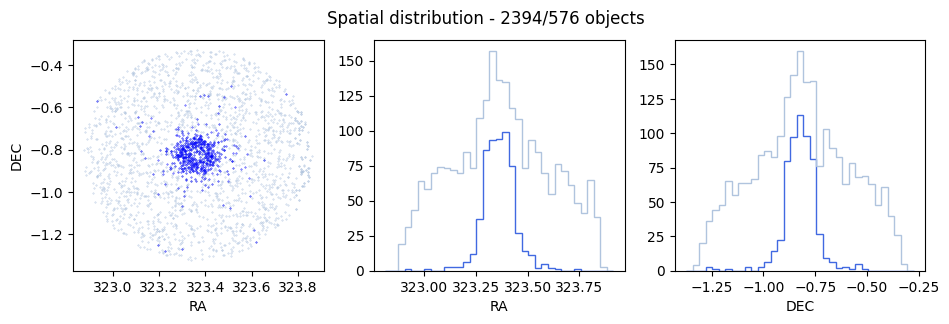

In [55]:
# Create a figure with 3 subplots (ax1, ax2, ax3) in a single row
f, (ax1, ax2, ax3) = plt.subplots(1, 3)
f.set_size_inches(11, 3)  # Set figure size

# Calculate the number of field stars and Messier 2 stars
N = mask.sum()  # Total number of field stars passing the mask
N_M2 = M2_mask.sum()  # Total number of Messier 2 stars

# Set the overall title of the figure, showing the counts of selected objects
f.suptitle(f'Spatial distribution - {N}/{N_M2} objects')

# Extract right ascension (RA) and declination (DEC) from the dataset
ra = matched['ra']  # Right ascension
dec = matched['dec']  # Declination

# Set up the RA and DEC ranges for plotting based on a given cone radius
cone_radius_deg = 0.5

ra_range = coords[0] + np.array(
    [-1.1 * cone_radius_deg, 1.1 * cone_radius_deg]
)

dec_range = coords[1] + np.array(
    [-1.1 * cone_radius_deg, 1.1 * cone_radius_deg]
)

im = ax1.scatter(ra[mask], dec[mask], c='lightsteelblue', s=0.1)
im = ax1.scatter(ra[M2_mask], dec[M2_mask], c='b', s=0.1)
ax1.set_xlabel('RA')
ax1.set_ylabel('DEC')
ax2.hist([ra[mask], ra[M2_mask]], bins=35, range=ra_range, density=False, color=['lightsteelblue', 'royalblue'], histtype='step')
ax2.set_xlabel('RA')
ax3.hist([dec[mask], dec[M2_mask]], bins=35, range=dec_range, density=False, color=['lightsteelblue', 'royalblue'], histtype='step')
ax3.set_xlabel('DEC')

## H.R. Diagrams 

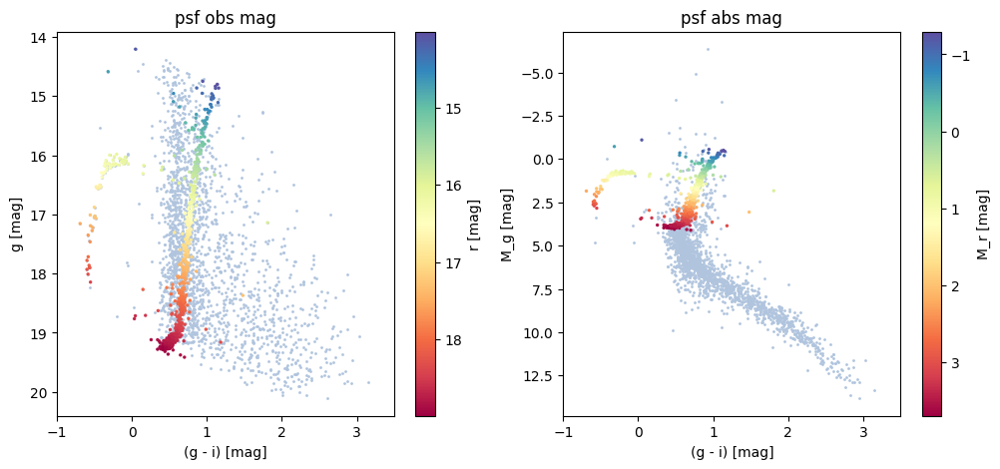

In [52]:
# Calculate color (g - i) and magnitudes for plotting
x = matched[f'mag_psf_g'] - matched[f'mag_psf_i']  # Color index (g - i)
y = matched[f'mag_psf_g']  # Magnitude in the g band
z = matched[f'mag_psf_r']  # Magnitude in the r band (for color coding)

# Create two subplots side by side
f, (ax1, ax2) = plt.subplots(1, 2)
f.set_size_inches(12, 5)

# Scatter plot of observed magnitudes for field stars and Messier 2 stars
ax1.scatter(x[mask], y[mask], s=1, c='lightsteelblue')  # Field stars
sc = ax1.scatter(x[M2_mask], y[M2_mask], c=z[M2_mask], s=2, cmap='Spectral_r')  # Messier 2 stars
ax1.set_title(f'{apperture} obs mag')

# Add color bar for the r magnitude and set labels
cax = plt.colorbar(sc, ax=ax1)
cax.ax.set_ylabel('r [mag]')  # Color bar label for r magnitude
cax.ax.invert_yaxis()  # Invert color bar axis to follow astronomical convention

# Set x and y labels for the first plot
ax1.set_xlabel(f'(g - i) [mag]')  # Label x-axis as color (g - i)
ax1.set_ylabel(f'g [mag]')  # Label y-axis as g magnitude
ax1.set_xlim(-1, 3.5)  # Set limits for x-axis (g - i)
ax1.invert_yaxis()  # Invert y-axis for magnitude (smaller values = brighter stars)

# Convert field and Messier 2 magnitudes to absolute magnitudes using distance modulus correction
Y = y + mabs_corr  # Field stars' absolute magnitude
M2_Y = y + M2_mabs_corr  # Messier 2 stars' absolute magnitude
M2_Z = z + M2_mabs_corr  # Messier 2 corrected r magnitudes (for color)

# Scatter plot of absolute magnitudes for field and Messier 2 stars
ax2.scatter(x[mask & ~M2_mask], Y[mask & ~M2_mask], s=1, c='lightsteelblue')  # Field stars
sc = ax2.scatter(x[M2_mask], M2_Y[M2_mask], c=M2_Z[M2_mask], s=2, cmap='Spectral_r')  # Messier 2 stars
ax2.set_title(f'{apperture} abs mag')  # Set title for second plot

cax = plt.colorbar(sc, ax=ax2)
cax.ax.set_ylabel('M_r [mag]')
cax.ax.invert_yaxis()
ax2.set_xlabel(f'(g - i) [mag]')
ax2.set_ylabel(f'M_g [mag]')
ax2.set_xlim(-1, 3.5)
ax2.invert_yaxis()